# Imports

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.special import ellipk

# Global parameters
L = 1.0   # dolzina nihala [m]
g = 9.81  # tezni pospesek [m/s^2]
T0 = 2 * np.pi * np.sqrt(L / g)
theta0_deg = [10, 30, 60, 90, 120, 150]

omega0 = 1.0                        # Duffing [1/s]
alpha_list = [0.5, -0.1]            # utrjena / mehcana vzmet
A_list = np.linspace(0.2, 1.8, 17)  # zacetne amplitude

rtol, atol = 1e-10, 1e-12

# Funkcije

In [16]:
# Simbolno: razvoj T/T0 = (2/pi) K(m), m = sin^2(theta0/2)
th0 = sp.symbols("theta_0", positive=True)
T_rel_sym = 2 / sp.pi * sp.elliptic_k(sp.sin(th0 / 2)**2)
T_rel_series = sp.series(T_rel_sym, th0, 0, 6).removeO()

In [17]:
# Simbolno: harmonsko ravnovesje za Duffing, x = A cos(w t)
t, w, w0, A = sp.symbols("t omega omega_0 A", positive=True)
al = sp.symbols("alpha", real=True)
x_ans = A * sp.cos(w * t)
residual = sp.diff(x_ans, t, 2) + w0**2 * x_ans + al * x_ans**3

# projekcija na cos(w t) mora biti 0
c1 = sp.simplify(sp.integrate(residual * sp.cos(w * t), (t, 0, 2 * sp.pi / w)) * w / sp.pi)
w_hb = sp.solve(c1, w)[0]                                  # harmonsko ravnovesje
w_pert = sp.series(w_hb, A, 0, 3).removeO()                # 1. red perturbacije
omega_pert = sp.lambdify((A, al, w0), w_pert, "numpy")

In [18]:
def rhs_nihalo(t, y):
    theta, omega_v = y
    return [omega_v, -g / L * np.sin(theta)]

def rhs_duffing(t, y, alpha):
    x, v = y
    return [v, -omega0**2 * x - alpha * x**3]

def prehod(t, y, *args):
    # pozitiven prehod skozi 0
    return y[0]
prehod.direction = 1

def perioda(rhs, y0, t_end, args=()):
    # T = razmik med zaporednima pozitivnima prehodoma
    sol = solve_ivp(rhs, (0, t_end), y0, args=args, events=prehod,
                    rtol=rtol, atol=atol, dense_output=True)
    t_ev = sol.t_events[0]
    return np.mean(np.diff(t_ev)), sol

def T_elip(theta0):
    # ellipk sprejme m = k^2
    return 4 * np.sqrt(L / g) * ellipk(np.sin(theta0 / 2)**2)

# Testno območje

In [19]:
# Pripravljalna naloga, theta0 = 60 st.
th = np.pi / 3
k = np.sin(th / 2)
T_approx = T0 * (1 + th**2 / 16)

print(f"T0       = {T0:.4f} s")
print(f"k        = {k:.4f}")
print(f"T(60)    = {T_approx:.4f} s  (priblizek)")
print(f"(T-T0)/T0 = {100 * (T_approx - T0) / T0:.2f} %")
print(f"T_elip   = {T_elip(th):.4f} s  (tocno)")

T0       = 2.0061 s
k        = 0.5000
T(60)    = 2.1436 s  (priblizek)
(T-T0)/T0 = 6.85 %
T_elip   = 2.1529 s  (tocno)


In [20]:
display(sp.Eq(sp.Symbol("T/T_0"), T_rel_series))
display(sp.Eq(w, w_hb))
display(sp.Eq(w, w_pert))

Eq(T/T_0, 11*theta_0**4/3072 + theta_0**2/16 + 1)

Eq(omega, sqrt(3*A**2*alpha + 4*omega_0**2)/2)

Eq(omega, 3*A**2*alpha/(8*omega_0) + omega_0)

# Naloga 1

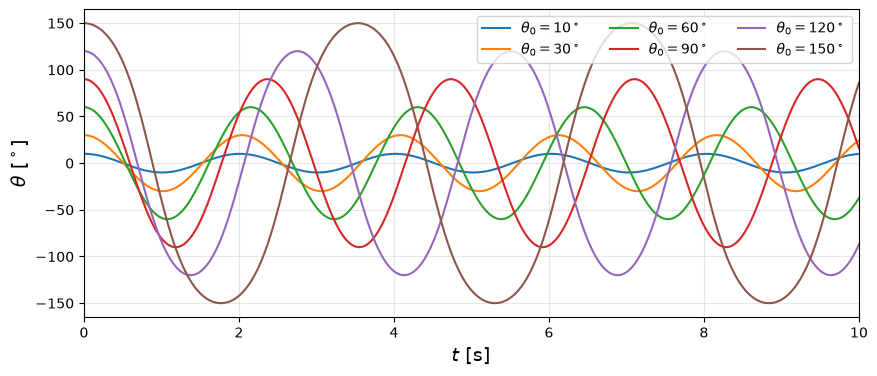

In [21]:
t_end = 10.0
t_plot = np.linspace(0, t_end, 2000)

rez_nihalo = {}  # theta0_deg -> (T_num, sol)
for deg in theta0_deg:
    rez_nihalo[deg] = perioda(rhs_nihalo, [np.radians(deg), 0.0], t_end)

fig = plt.figure(figsize=(10, 4))
ax = fig.add_subplot(111)
for deg in theta0_deg:
    sol = rez_nihalo[deg][1]
    ax.plot(t_plot, np.degrees(sol.sol(t_plot)[0]), label=rf"$\theta_0 = {deg}^\circ$")
ax.set_xlabel("$t$ [s]", fontsize=14)
ax.set_ylabel(r"$\theta$ [$^\circ$]", fontsize=14)
ax.set_xlim(0, t_end)
ax.legend(loc="upper right", ncol=3)
ax.grid(alpha=0.3)
plt.show()

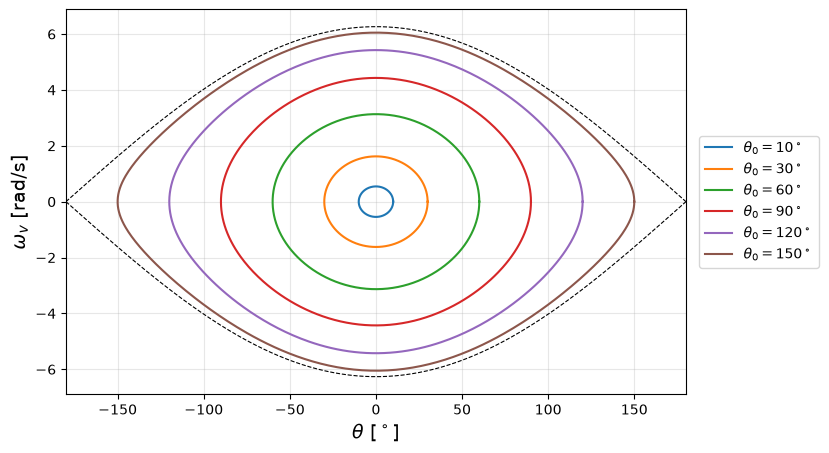

In [22]:
# Fazni diagram (theta, omega_v) + separatrisa omega_v = +-2 sqrt(g/L) cos(theta/2)
th_sep = np.linspace(-np.pi, np.pi, 400)
w_sep = 2 * np.sqrt(g / L) * np.cos(th_sep / 2)

fig = plt.figure(figsize=(8, 5))
ax = fig.add_subplot(111)
for deg in theta0_deg:
    T_num, sol = rez_nihalo[deg]
    t_per = np.linspace(0, T_num, 500)
    theta, omega_v = sol.sol(t_per)
    ax.plot(np.degrees(theta), omega_v, label=rf"$\theta_0 = {deg}^\circ$")
for s in (-1, 1):
    ax.plot(np.degrees(th_sep), s * w_sep, "--", color="black", linewidth=0.8)
ax.set_xlabel(r"$\theta$ [$^\circ$]", fontsize=14)
ax.set_ylabel(r"$\omega_v$ [rad/s]", fontsize=14)
ax.set_xlim(-180, 180)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
ax.grid(alpha=0.3)
plt.show()

Fazni digram prizakuje trajektorije $(\theta, \omega_v)$ za vseh šest začetnih kotov, vsako čez eno periodo. Uporabljene so že izračunane rešitve, zato dodatnega računanja ni.

Separatrisa $\omega_v = \pm 2\sqrt{g/L},\cos(\theta/2)$ (črtkano) je meja med nihanjem in kroženjem nihala.

Na sliki se lepo vidi nelinearnost. Pri $10^\circ$ in $30^\circ$ so trajektorije skoraj elipse kot pri harmonskem nihalu. Z večanjem kota se raztegujejo proti separatrisi in pri $150^\circ$ ob robovih postanejo skoraj ostre.

# Naloga 2

In [23]:
print(f"{'th0[deg]':>8} {'th0[rad]':>9} {'T_num[s]':>12} {'T_elip[s]':>12} {'razlika[%]':>11} {'T_pribl[s]':>11}")
for deg in theta0_deg:
    th = np.radians(deg)
    T_num = rez_nihalo[deg][0]
    T_ex = T_elip(th)
    T_pr = T0 * (1 + th**2 / 16)
    print(f"{deg:8d} {th:9.4f} {T_num:12.8f} {T_ex:12.8f} {100 * abs(T_num - T_ex) / T_ex:11.1e} {T_pr:11.4f}")

th0[deg]  th0[rad]     T_num[s]    T_elip[s]  razlika[%]  T_pribl[s]
      10    0.1745   2.00989263   2.00989263     1.7e-10      2.0099
      30    0.5236   2.04098989   2.04098989     9.1e-10      2.0404
      60    1.0472   2.15287467   2.15287467     4.5e-09      2.1436
      90    1.5708   2.36784195   2.36784195     1.3e-08      2.3154
     120    2.0944   2.75408983   2.75408983     1.3e-08      2.5560
     150    2.6180   3.53509819   3.53509819     3.7e-08      2.8654


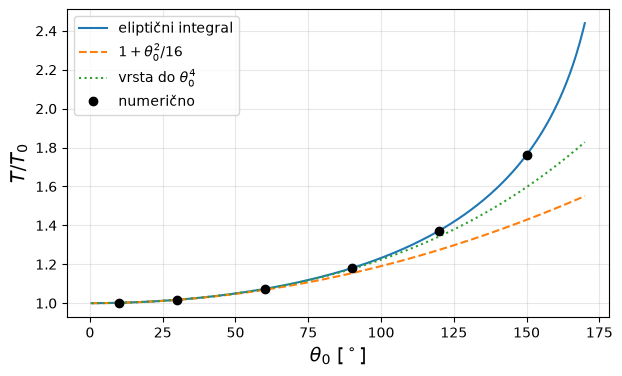

In [24]:
th_fine = np.linspace(0.01, np.radians(170), 300)
T_rel_series_np = sp.lambdify(th0, T_rel_series, "numpy")

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot(np.degrees(th_fine), T_elip(th_fine) / T0, label="eliptični integral")
ax.plot(np.degrees(th_fine), 1 + th_fine**2 / 16, "--", label=r"$1 + \theta_0^2/16$")
ax.plot(np.degrees(th_fine), T_rel_series_np(th_fine), ":", label=r"vrsta do $\theta_0^4$")
ax.plot(theta0_deg, [rez_nihalo[d][0] / T0 for d in theta0_deg], "o", color="black", label="numerično")
ax.set_xlabel(r"$\theta_0$ [$^\circ$]", fontsize=14)
ax.set_ylabel(r"$T/T_0$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Naloga 3

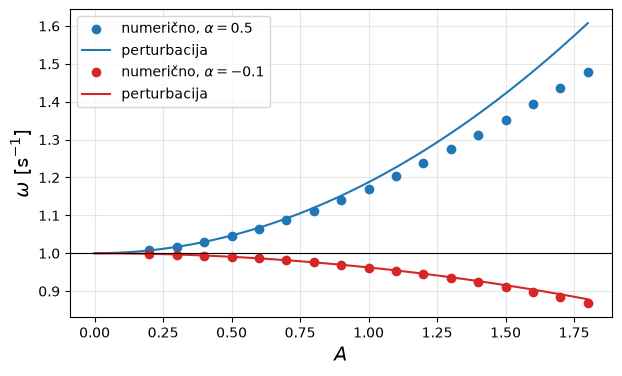

In [25]:
rez_duffing = {}  # alpha -> omega_num(A)
for alpha in alpha_list:
    omega_num = []
    for A0 in A_list:
        T_num, _ = perioda(rhs_duffing, [A0, 0.0], 40.0, args=(alpha,))
        omega_num.append(2 * np.pi / T_num)
    rez_duffing[alpha] = np.array(omega_num)

A_fine = np.linspace(0, 1.8, 200)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for alpha, c in zip(alpha_list, ["C0", "C3"]):
    ax.plot(A_list, rez_duffing[alpha], "o", color=c, label=rf"numerično, $\alpha = {alpha}$")
    ax.plot(A_fine, omega_pert(A_fine, alpha, omega0), "-", color=c, label="perturbacija")
ax.axhline(omega0, color="black", linewidth=0.8)
ax.set_xlabel("$A$", fontsize=14)
ax.set_ylabel(r"$\omega$ [s$^{-1}$]", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

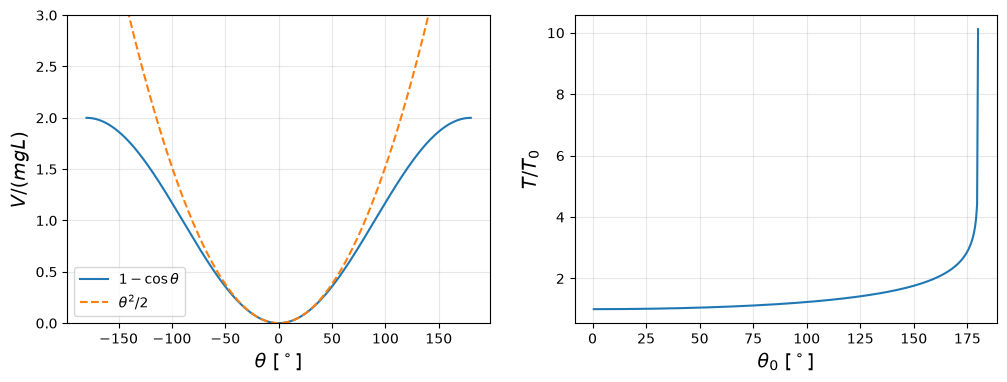

In [26]:
# Potencial nihala vs. harmonski potencial (V / mgL)
th_v = np.linspace(-np.pi, np.pi, 400)

fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(121)
ax.plot(np.degrees(th_v), 1 - np.cos(th_v), label=r"$1 - \cos\theta$")
ax.plot(np.degrees(th_v), th_v**2 / 2, "--", label=r"$\theta^2/2$")
ax.set_xlabel(r"$\theta$ [$^\circ$]", fontsize=14)
ax.set_ylabel(r"$V/(mgL)$", fontsize=14)
ax.set_ylim(0, 3)
ax.legend()
ax.grid(alpha=0.3)

# T -> inf, ko theta0 -> pi
ax = fig.add_subplot(122)
th_div = np.linspace(0.01, np.pi - 1e-6, 400)
ax.plot(np.degrees(th_div), T_elip(th_div) / T0)
ax.set_xlabel(r"$\theta_0$ [$^\circ$]", fontsize=14)
ax.set_ylabel(r"$T/T_0$", fontsize=14)
ax.grid(alpha=0.3)
plt.show()

# Razmislek 2

In [27]:
# Kriticna amplituda: vrh potenciala V(x) = w0^2 x^2/2 + alpha x^4/4
xs = sp.symbols("x", real=True)
V = w0**2 * xs**2 / 2 + al * xs**4 / 4
display(sp.solve(sp.diff(V, xs), xs))

A_krit = np.sqrt(omega0**2 / abs(alpha_list[1]))
print(f"A_krit (alpha = {alpha_list[1]}) = {A_krit:.3f}")

# Odstopanje perturbacije od numerike
for alpha in alpha_list:
    napaka = 100 * np.abs(omega_pert(A_list, alpha, omega0) - rez_duffing[alpha]) / rez_duffing[alpha]
    A_1proc = A_list[napaka < 1].max()
    print(f"alpha = {alpha:+.1f}: napaka < 1 % do A = {A_1proc:.1f}, pri A = 1.8 je {napaka[-1]:.1f} %")

[0, -omega_0*sqrt(-1/alpha), omega_0*sqrt(-1/alpha)]

A_krit (alpha = -0.1) = 3.162
alpha = +0.5: napaka < 1 % do A = 0.9, pri A = 1.8 je 8.7 %
alpha = -0.1: napaka < 1 % do A = 1.7, pri A = 1.8 je 1.2 %


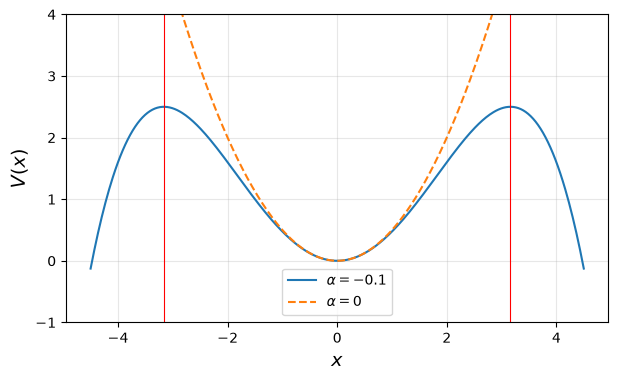

In [28]:
x_v = np.linspace(-4.5, 4.5, 400)
V_np = sp.lambdify((xs, al, w0), V, "numpy")

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
ax.plot(x_v, V_np(x_v, alpha_list[1], omega0), label=rf"$\alpha = {alpha_list[1]}$")
ax.plot(x_v, x_v**2 / 2, "--", label=r"$\alpha = 0$")
for s in (-1, 1):
    ax.axvline(s * A_krit, color="red", linewidth=0.8)
ax.set_xlabel("$x$", fontsize=14)
ax.set_ylabel("$V(x)$", fontsize=14)
ax.set_ylim(-1, 4)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 3

max |R| = 3.590 rad/s^2


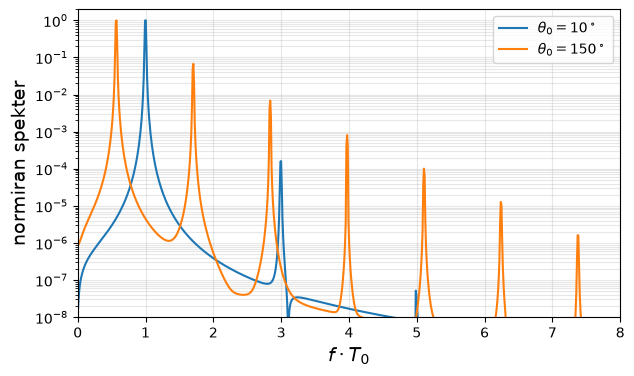

In [29]:
# Superpozicija: residual R = th'' + (g/L) sin(th) za th = th1 + th2
t_s = np.linspace(0, 10, 2000)
th1 = rez_nihalo[30][1].sol(t_s)
th2 = rez_nihalo[60][1].sol(t_s)
th_sum = th1[0] + th2[0]
dd_sum = np.gradient(th1[1] + th2[1], t_s)
R = dd_sum + g / L * np.sin(th_sum)
print(f"max |R| = {np.max(np.abs(R)):.3f} rad/s^2")

# Spekter theta(t): visji harmoniki (lihi) pri velikih odklonih
T_sp = 200.0
t_sp = np.linspace(0, T_sp, 2**15, endpoint=False)
fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(111)
for deg in (10, 150):
    _, sol = perioda(rhs_nihalo, [np.radians(deg), 0.0], T_sp)
    th_t = sol.sol(t_sp)[0]
    spek = np.abs(np.fft.rfft(th_t * np.hanning(len(th_t))))
    f_os = np.fft.rfftfreq(len(t_sp), t_sp[1] - t_sp[0])
    ax.plot(f_os * T0, spek / spek.max(), label=rf"$\theta_0 = {deg}^\circ$")
ax.set_yscale("log")
ax.set_xlim(0, 8)
ax.set_ylim(1e-8, 2)
ax.set_xlabel(r"$f \cdot T_0$", fontsize=14)
ax.set_ylabel("normiran spekter", fontsize=14)
ax.legend()
ax.grid(alpha=0.3, which="both")
plt.show()